# Bank Marketing Dataset — Python ข้อ 1–15
วิเคราะห์ข้อมูลด้วย Pandas, Matplotlib และ Seaborn จากไฟล์ `bank-full.csv` (45,211 แถว)  
**ข้อ 1–10:** EDA | **ข้อ 11–15:** ตรวจสอบสมมติฐานด้วยสถิติเชิงพรรณนา  
เรียกใช้เซลล์จากบนลงล่าง (Run All) โดยวาง `bank-full.csv` ในโฟลเดอร์เดียวกับ Notebook หรืออัปโหลดไฟล์เข้า Colab ก่อน

In [17]:
# หากยังไม่มีไลบรารี ให้รัน: %pip install pandas numpy matplotlib seaborn scipy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('bank-full.csv', sep=',')
df['subscribed'] = (df['y'] == 'yes').astype(int)
print('Dataset:', df.shape, '| Overall subscription rate:', f"{df['subscribed'].mean():.2%}")
print(df[['duration','balance','campaign','poutcome','y']].head())

def rates_by(column, data=df):
    return (data.groupby(column, observed=True)['subscribed']
                .agg(rate='mean', total='size', subscribed='sum')
                .assign(rate_pct=lambda x: x['rate']*100)
                .sort_values('rate_pct', ascending=False))

def percent_stacked(column, title):
    tab = pd.crosstab(df[column], df['y'], normalize='index').mul(100)
    tab = tab.reindex(columns=['no','yes'], fill_value=0)
    ax = tab.plot(kind='bar', stacked=True, color=['#8fbad4','#e39770'], figsize=(10,5))
    ax.set(title=title, xlabel=column, ylabel='Within-group percentage (%)', ylim=(0,100))
    ax.legend(title='Subscribed', bbox_to_anchor=(1.02,1), loc='upper left')
    plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()
    display(tab.round(2))

Dataset: (45211, 18) | Overall subscription rate: 11.70%
   duration  balance  campaign poutcome   y
0       261     2143         1  unknown  no
1       151       29         1  unknown  no
2        76        2         1  unknown  no
3        92     1506         1  unknown  no
4       198        1         1  unknown  no


## ข้อ 1 — Distribution of Duration
สร้าง Histogram และ Boxplot ตรวจสอบความเบ้และ Outliers (เกณฑ์ IQR)

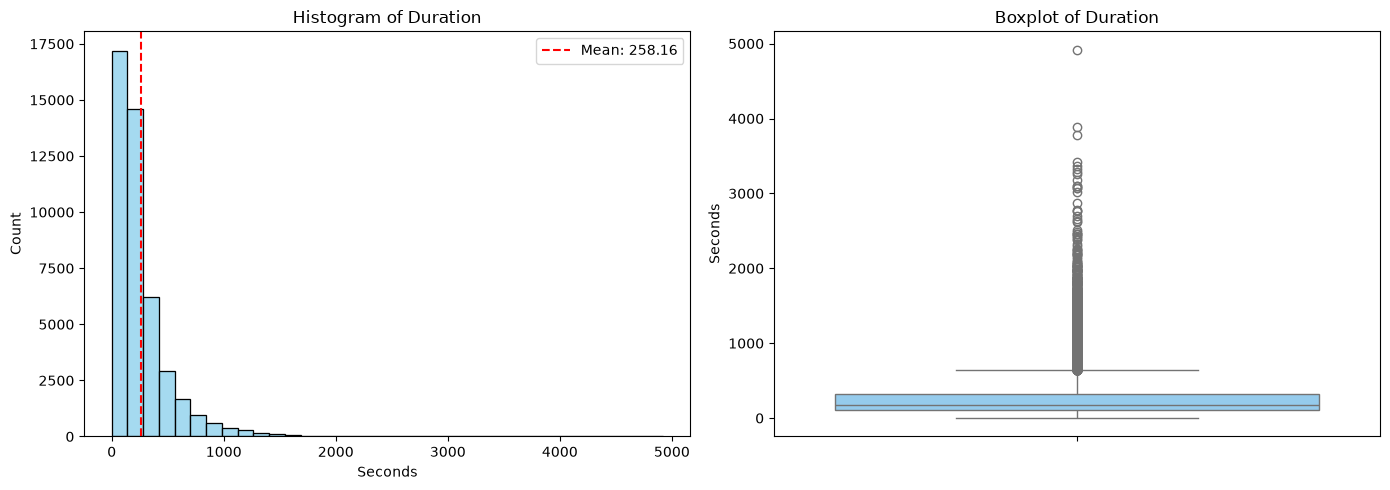

Mean=258.16, Median=180.00, Skewness=3.144
Upper outlier threshold=643.00 seconds, Outliers=3,235 rows
ข้อสรุป: Right-skewed


In [18]:
duration = df['duration']
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.histplot(duration, bins=35, ax=axes[0], color='skyblue')
axes[0].axvline(duration.mean(), color='red', ls='--', label=f'Mean: {duration.mean():.2f}')
axes[0].set(title='Histogram of Duration', xlabel='Seconds'); axes[0].legend()
sns.boxplot(y=duration, ax=axes[1], color='lightskyblue')
axes[1].set(title='Boxplot of Duration', ylabel='Seconds')
plt.tight_layout(); plt.show()
q1, q3 = duration.quantile([.25,.75]); upper = q3 + 1.5*(q3-q1)
print(f'Mean={duration.mean():.2f}, Median={duration.median():.2f}, Skewness={duration.skew():.3f}')
print(f'Upper outlier threshold={upper:.2f} seconds, Outliers={(duration>upper).sum():,} rows')
print('ข้อสรุป:', 'Right-skewed' if duration.skew()>0 else 'Not right-skewed')

## ข้อ 2 — Duration vs Target
เปรียบเทียบระยะเวลาสนทนาระหว่าง `yes` กับ `no`

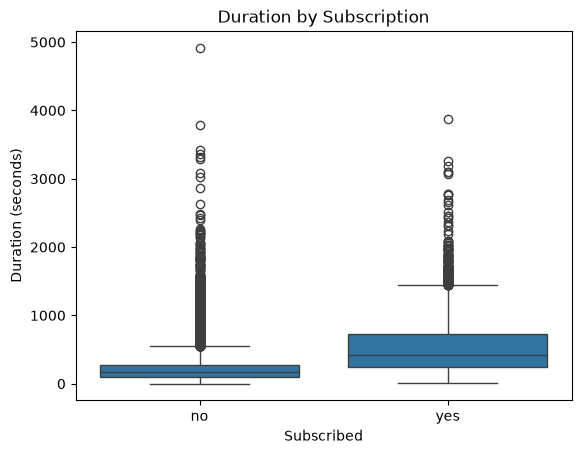

,count,mean,median,std
y,,,,
no,39922,221.18,164.0,207.38
yes,5289,537.29,426.0,392.53


กลุ่มที่มี median duration สูงกว่า: yes


In [19]:
sns.boxplot(data=df, x='y', y='duration', order=['no','yes'], showfliers=True)
plt.title('Duration by Subscription'); plt.xlabel('Subscribed'); plt.ylabel('Duration (seconds)'); plt.show()
display(df.groupby('y')['duration'].agg(['count','mean','median','std']).round(2))
print('กลุ่มที่มี median duration สูงกว่า:', df.groupby('y')['duration'].median().idxmax())

## ข้อ 3 — Categorical Variables Exploration
แต่ละตัวแปรสร้าง Countplot และ Barplot อัตราการสมัคร; เส้นประแสดงอัตราเฉลี่ยรวม

In [ ]:
overall = 100*df['subscribed'].mean()
for col in ['job','marital','education']:
    order = df[col].value_counts().index
    fig, ax = plt.subplots(1,2,figsize=(16,5))
    sns.countplot(data=df, x=col, order=order, ax=ax[0], color='#8fbad4')
    ax[0].set_title(f'{col}: Customer Count')
    r = rates_by(col).reindex(order)
    sns.barplot(x=r.index, y=r['rate_pct'].values, ax=ax[1], color='#e39770', errorbar=None)
    ax[1].axhline(overall,color='red',linestyle='--',label=f'Overall {overall:.2f}%')
    ax[1].set(title=f'{col}: Subscription rate', xlabel=col, ylabel='Subscription rate (%)'); ax[1].legend()
    for a in ax: a.tick_params(axis='x',rotation=55)
    plt.tight_layout(); plt.show()
    print(f'{col}: Above overall subscription rate ({overall:.2f}%)')
    display(rates_by(col).query('rate_pct > @overall')[['rate_pct','total']].round(2))

NameError: name 'df' is not defined

## ข้อ 4 — Correlation Matrix
Pearson correlation สำหรับตัวแปรตัวเลข 6 ตัว; `pdays=-1` หมายถึงไม่เคยติดต่อก่อนหน้า ควรระวังการตีความ

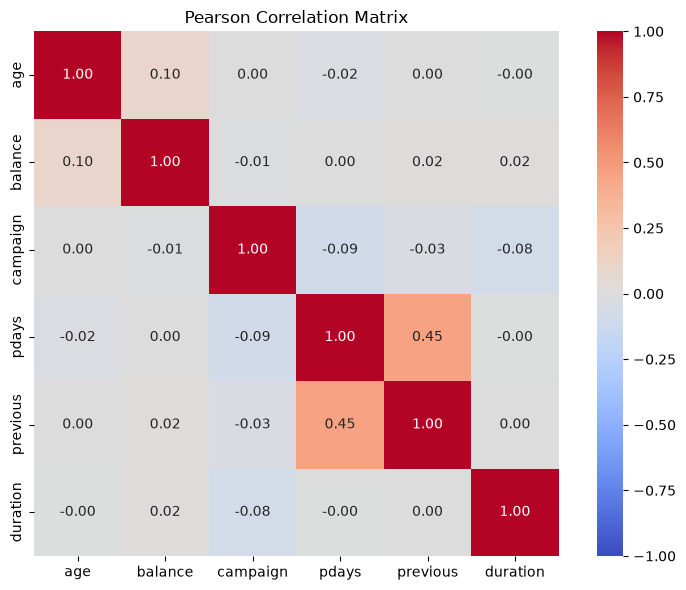

Top absolute correlations:


Pearson r
pdays    previous   0.454820
age      balance    0.097783
campaign pdays     -0.088628
         duration  -0.084570
         previous  -0.032855
age      pdays     -0.023758
balance  duration   0.021560
         previous   0.016674

In [21]:
numeric = ['age','balance','campaign','pdays','previous','duration']
corr = df[numeric].corr(method='pearson')
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,fmt='.2f',cmap='coolwarm',center=0,vmin=-1,vmax=1,square=True)
plt.title('Pearson Correlation Matrix'); plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack().sort_values(key=abs,ascending=False)
print('Top absolute correlations:'); display(pairs.head(8).rename('Pearson r').to_frame())

## ข้อ 5 — Temporal Pattern Analysis
คำนวณ **อัตราการสมัคร** รายเดือนและวันที่ของเดือน (ไม่ใช่วันในสัปดาห์); ข้อมูลมีหลายปี แต่ไม่มีตัวแปรปีให้ใช้โดยตรง จึงไม่ควรยืนยัน Seasonality

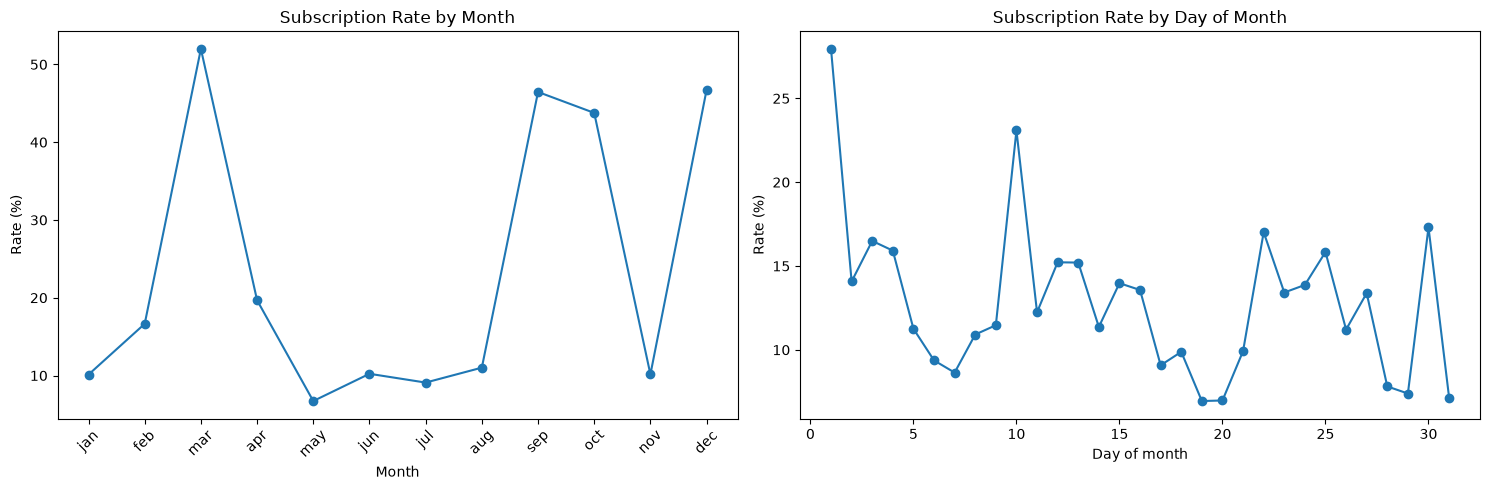

Highest months:


,rate_pct,total
month,,
mar,51.99,477
dec,46.73,214
sep,46.46,579
oct,43.77,738
apr,19.68,2932


Highest days:


,rate_pct,total
day,,
1,27.95,322
10,23.09,524
30,17.31,1566
22,17.02,905
3,16.50,1079


In [22]:
MONTHS = ['jan','feb','mar','apr','may','jun',
          'jul','aug','sep','oct','nov','dec']

# แปลง yes/no เป็น 1/0 เพื่อคำนวณ Subscription Rate
df['subscribed'] = (df['y'] == 'yes').astype(int)

# Group by month และ day
by_month = df.groupby('month')['subscribed'].agg(['mean', 'size']).reindex(MONTHS, fill_value=0)
by_day = df.groupby('day')['subscribed'].agg(['mean', 'size']).reindex(range(1, 32), fill_value=0)

# Plot
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

axs[0].plot(by_month.index, by_month['mean'] * 100, marker='o')
axs[0].set(title='Subscription Rate by Month', xlabel='Month', ylabel='Rate (%)')
axs[0].tick_params(axis='x', rotation=45)

axs[1].plot(by_day.index, by_day['mean'] * 100, marker='o')
axs[1].set(title='Subscription Rate by Day of Month', xlabel='Day of month', ylabel='Rate (%)')

plt.tight_layout()
plt.show()

# Highest months
print('Highest months:')
display(
    (by_month * [100, 1])
    .rename(columns={'mean': 'rate_pct', 'size': 'total'})
    .sort_values('rate_pct', ascending=False)
    .head()
    .round(2)
)

# Highest days
print('Highest days:')
display(
    (by_day * [100, 1])
    .rename(columns={'mean': 'rate_pct', 'size': 'total'})
    .sort_values('rate_pct', ascending=False)
    .head()
    .round(2)
)

## ข้อ 6 — Balance Distribution
Histogram, Boxplot และอัตราการสมัครตามระดับยอดเงิน (Quartiles; ค่าซ้ำอาจทำให้จำนวน bins น้อยกว่า 4)

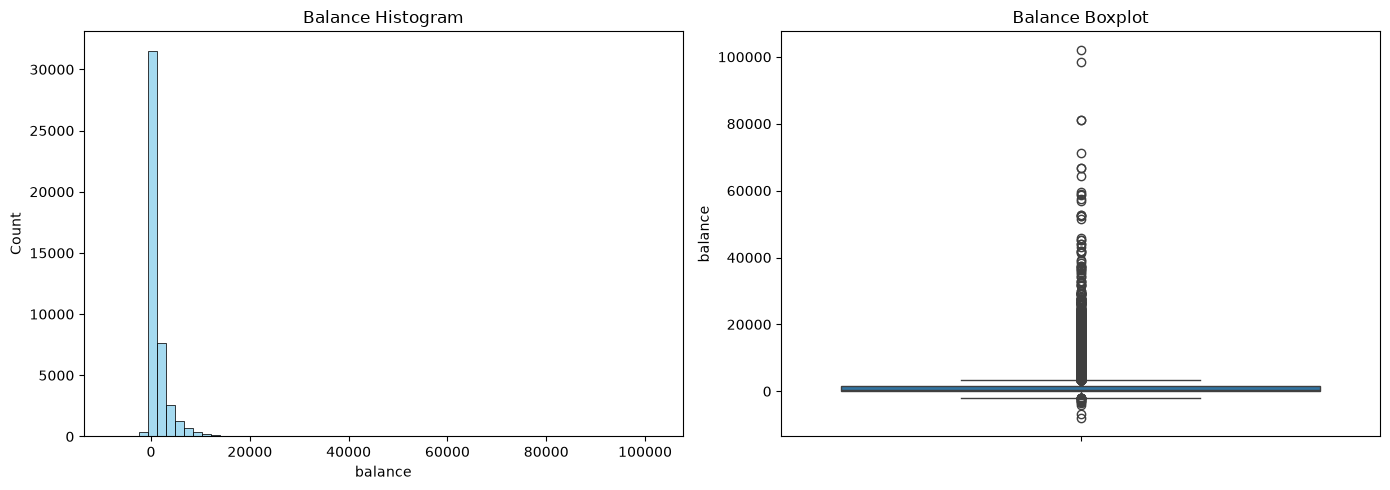

count     45211.00
mean       1362.27
std        3044.77
min       -8019.00
25%          72.00
50%         448.00
75%        1428.00
max      102127.00
Name: balance, dtype: float64
Skewness: 8.36


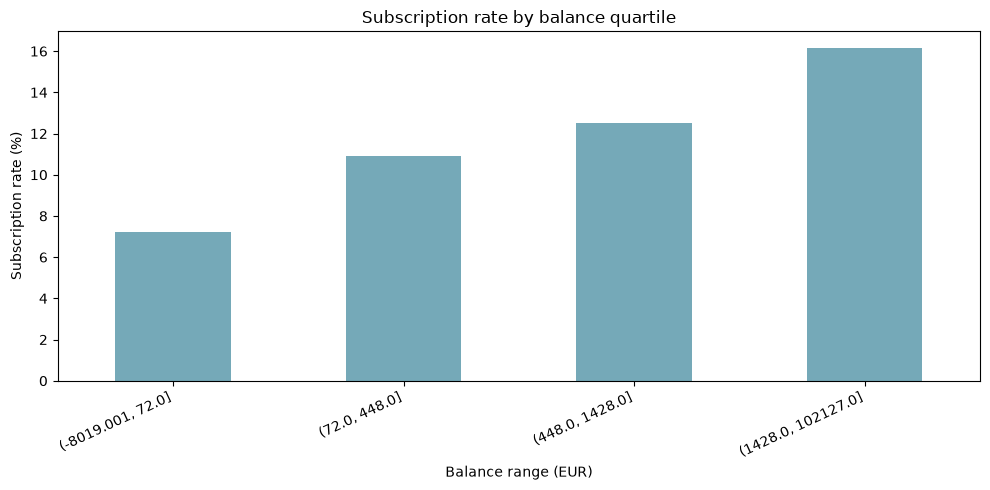

,rate_pct,size
balance,,
"(-8019.001, 72.0]",7.24,11317
"(72.0, 448.0]",10.89,11291
"(448.0, 1428.0]",12.52,11306
"(1428.0, 102127.0]",16.15,11297


In [23]:
fig,ax=plt.subplots(1,2,figsize=(14,5))
sns.histplot(data=df,x='balance',bins=60,ax=ax[0],color='skyblue');ax[0].set_title('Balance Histogram')
sns.boxplot(data=df,y='balance',ax=ax[1]);ax[1].set_title('Balance Boxplot')
plt.tight_layout();plt.show()
print(df['balance'].describe().round(2)); print('Skewness:',round(df['balance'].skew(),3))
balance_group = pd.qcut(df['balance'],q=4,duplicates='drop')
balance_rate=df.groupby(balance_group,observed=True)['subscribed'].agg(['mean','size'])
ax=(balance_rate['mean']*100).plot.bar(figsize=(10,5),color='#75a9b8')
ax.set(title='Subscription rate by balance quartile',ylabel='Subscription rate (%)',xlabel='Balance range (EUR)')
plt.xticks(rotation=25,ha='right');plt.tight_layout();plt.show()
display(balance_rate.assign(rate_pct=balance_rate['mean']*100)[['rate_pct','size']].round(2))

## ข้อ 7 — Loan & Housing Loan Analysis
เปรียบเทียบสัดส่วนสมัคร/ไม่สมัครภายในแต่ละกลุ่ม โดยไม่ใช้จำนวนดิบ

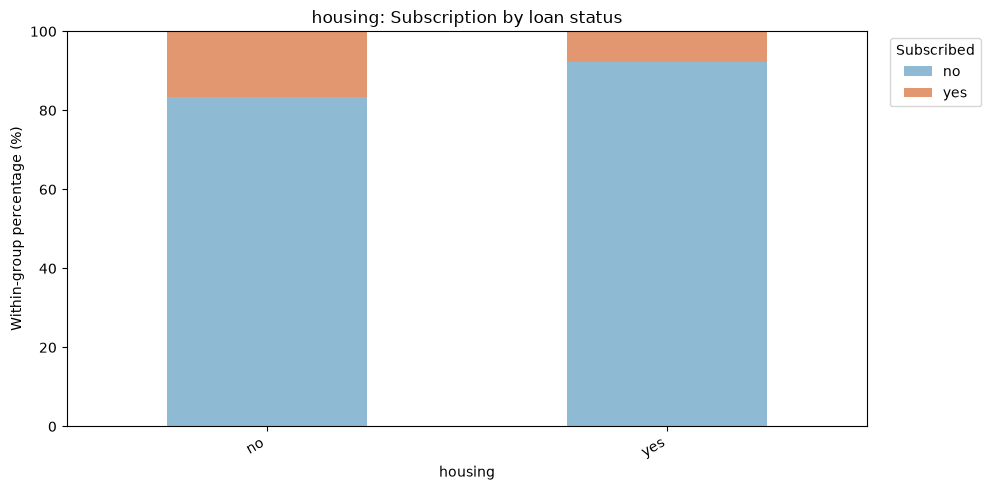

y,no,yes
housing,,
no,83.3,16.7
yes,92.3,7.7


,rate_pct,total
housing,,
no,16.7,20081
yes,7.7,25130


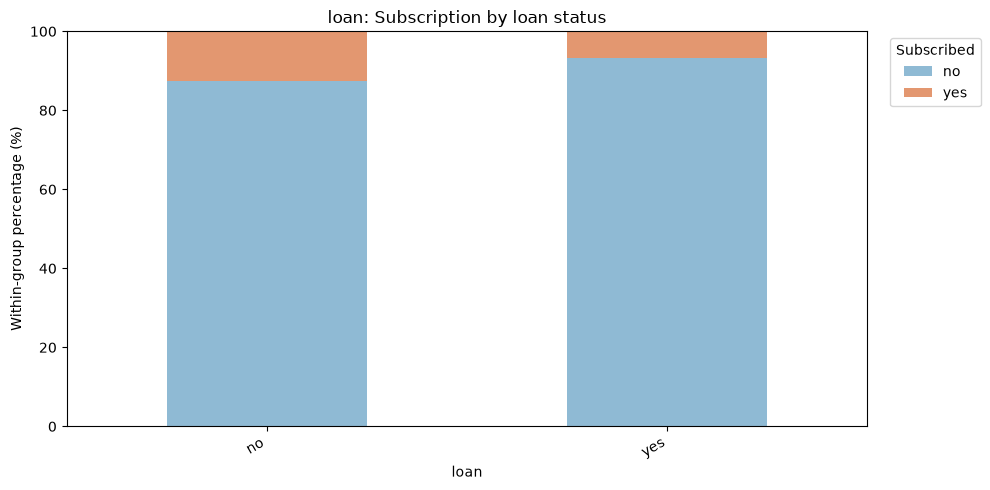

y,no,yes
loan,,
no,87.34,12.66
yes,93.32,6.68


,rate_pct,total
loan,,
no,12.66,37967
yes,6.68,7244


In [24]:
for col in ['housing','loan']:
    percent_stacked(col,f'{col}: Subscription by loan status')
    display(rates_by(col)[['rate_pct','total']].round(2))

## ข้อ 8 — Job Category Impact
กราฟ 100% Stacked Barplot โดยเรียงอาชีพจากอัตราสมัครสูงไปต่ำ

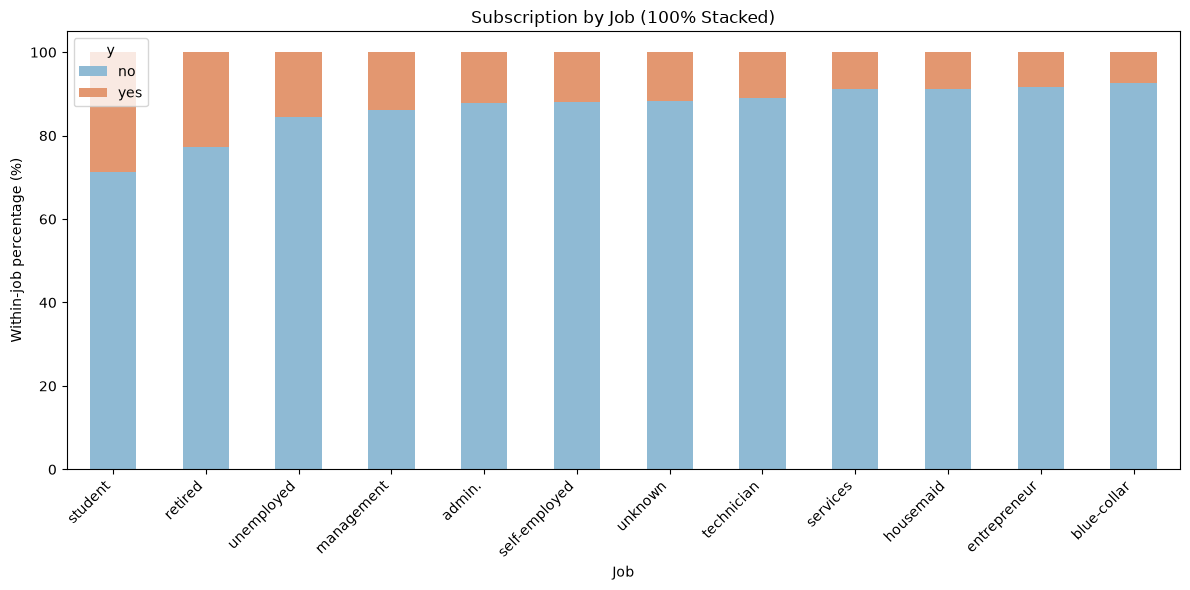

,rate_pct,total,subscribed
job,,,
student,28.68,938,269
retired,22.79,2264,516
unemployed,15.50,1303,202
management,13.76,9458,1301
admin.,12.20,5171,631
self-employed,11.84,1579,187
unknown,11.81,288,34
technician,11.06,7597,840
services,8.88,4154,369


Job with highest subscription rate: student


In [25]:
job_rates = rates_by('job')
job_table=pd.crosstab(df['job'],df['y'],normalize='index').mul(100).reindex(job_rates.index)
job_table=job_table.reindex(columns=['no','yes'])
job_table.plot(kind='bar',stacked=True,color=['#8fbad4','#e39770'],figsize=(12,6))
plt.title('Subscription by Job (100% Stacked)');plt.ylabel('Within-job percentage (%)');plt.xlabel('Job')
plt.xticks(rotation=45,ha='right');plt.tight_layout();plt.show()
display(job_rates[['rate_pct','total','subscribed']].round(2))
print('Job with highest subscription rate:',job_rates.index[0])

## ข้อ 9 — Campaign Effectiveness
Boxplot เปรียบเทียบจำนวนครั้งที่ติดต่อ และกราฟอัตราการสมัครตามจำนวนครั้ง (ขนาดตัวอย่างของค่าที่สูงอาจน้อย)

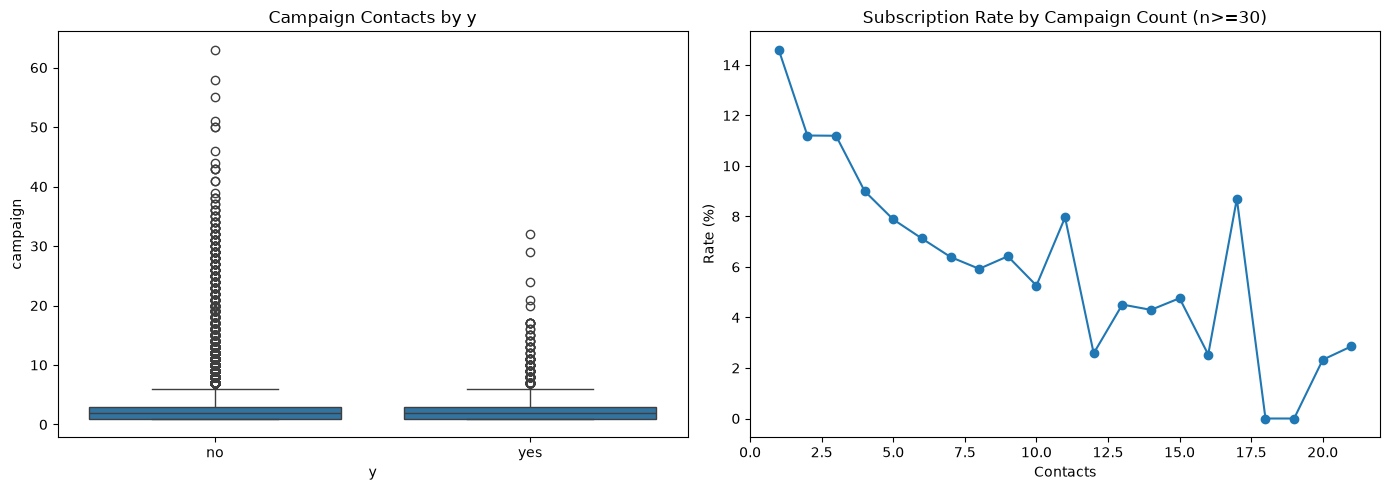

,count,mean,median
y,,,
no,39922,2.85,2.0
yes,5289,2.14,2.0


,size,rate_pct
campaign,,
1,17544,14.60
2,12505,11.20
3,5521,11.19
4,3522,9.00
5,1764,7.88
6,1291,7.13
7,735,6.39
8,540,5.93
9,327,6.42


In [26]:
fig, ax=plt.subplots(1,2,figsize=(14,5))
sns.boxplot(data=df,x='y',y='campaign',order=['no','yes'],ax=ax[0]);ax[0].set_title('Campaign Contacts by y')
campaign_rates=df.groupby('campaign')['subscribed'].agg(['mean','size'])
# แสดงเฉพาะกลุ่มที่มีอย่างน้อย 30 ตัวอย่างเพื่อให้กราฟตีความได้เหมาะสม
reliable=campaign_rates[campaign_rates['size']>=30]
ax[1].plot(reliable.index,reliable['mean']*100,marker='o')
ax[1].set(title='Subscription Rate by Campaign Count (n>=30)',xlabel='Contacts',ylabel='Rate (%)')
plt.tight_layout();plt.show()
display(df.groupby('y')['campaign'].agg(['count','mean','median']).round(2))
display(campaign_rates.assign(rate_pct=campaign_rates['mean']*100)[['size','rate_pct']].head(20).round(2))

## ข้อ 10 — Previous Outcome Influence
เปรียบเทียบอัตราสมัคร 4 กลุ่ม `success`, `failure`, `other`, `unknown`

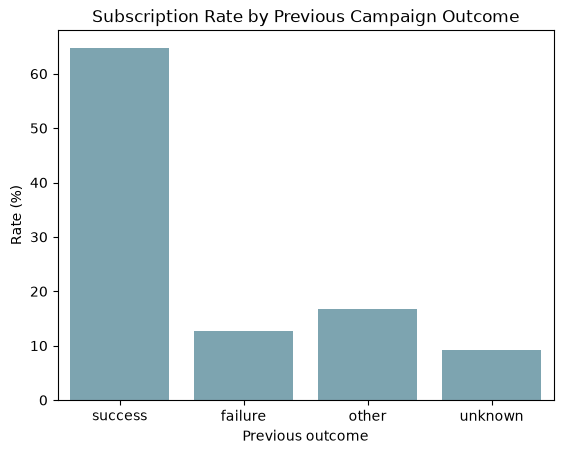

,rate_pct,total,subscribed
poutcome,,,
success,64.73,1511,978
failure,12.61,4901,618
other,16.68,1840,307
unknown,9.16,36959,3386


In [27]:
porder=['success','failure','other','unknown']
pdata=rates_by('poutcome').reindex(porder)
sns.barplot(x=pdata.index,y=pdata['rate_pct'].values,color='#75a9b8',errorbar=None)
plt.title('Subscription Rate by Previous Campaign Outcome');plt.ylabel('Rate (%)');plt.xlabel('Previous outcome');plt.show()
display(pdata[['rate_pct','total','subscribed']].round(2))

# ส่วนที่ 2 — ข้อ 11–15: ตรวจสอบสมมติฐาน
**หมายเหตุ:** ผลที่แสดงเป็นการสนับสนุน/ไม่สนับสนุนเชิงพรรณนา ไม่ใช่การยืนยันความมีนัยสำคัญทางสถิติหรือเหตุและผล

## ข้อ 11 — Duration Effect
สมมติฐาน: ลูกค้าที่สมัครมีเวลาสนทนายาวกว่าลูกค้าที่ไม่สมัคร (ใช้ Median ช่วยตัดสิน)

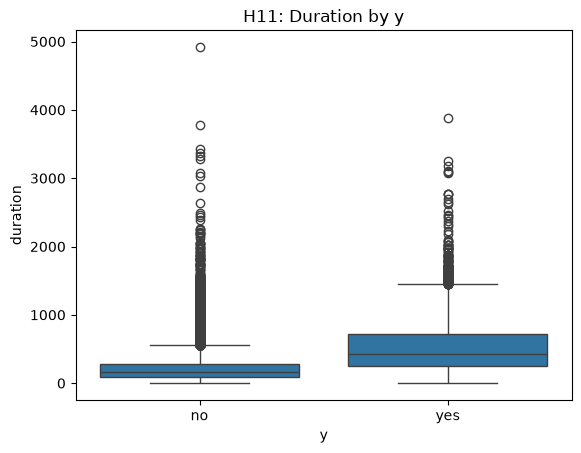

,mean,median,size
y,,,
no,221.18,164.0,39922
yes,537.29,426.0,5289


H11: ข้อมูลเชิงพรรณนาสนับสนุนสมมติฐาน


In [28]:
sns.boxplot(data=df,x='y',y='duration',order=['no','yes']);plt.title('H11: Duration by y');plt.show()
duration_stats=df.groupby('y')['duration'].agg(['mean','median','size'])
display(duration_stats.round(2))
print('H11:', 'ข้อมูลเชิงพรรณนาสนับสนุนสมมติฐาน' if duration_stats.loc['yes','median']>duration_stats.loc['no','median'] else 'ข้อมูลเชิงพรรณนาไม่สนับสนุนสมมติฐาน')

## ข้อ 12 — Education Impact
สมมติฐาน: `tertiary` มีอัตราการสมัครสูงกว่าระดับอื่นทั้งหมด

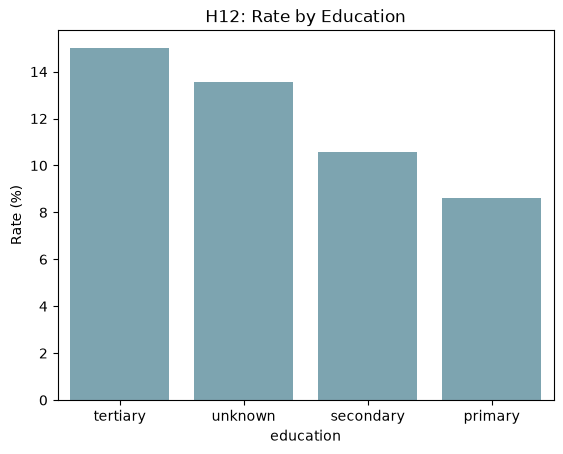

,rate_pct,total
education,,
tertiary,15.01,13301
unknown,13.57,1857
secondary,10.56,23202
primary,8.63,6851


H12: ข้อมูลเชิงพรรณนาสนับสนุนสมมติฐาน


In [29]:
ed = rates_by('education')
sns.barplot(x=ed.index,y=ed['rate_pct'].values,color='#75a9b8',errorbar=None)
plt.title('H12: Rate by Education');plt.ylabel('Rate (%)');plt.show()
display(ed[['rate_pct','total']].round(2))
print('H12:', 'ข้อมูลเชิงพรรณนาสนับสนุนสมมติฐาน' if ed.index[0]=='tertiary' else 'ข้อมูลเชิงพรรณนาไม่สนับสนุนสมมติฐาน (กลุ่มสูงสุดคือ '+str(ed.index[0])+')')

## ข้อ 13 — Loan Constraint
สมมติฐาน: กลุ่ม `loan=yes` มีอัตราการสมัครต่ำกว่า `loan=no`

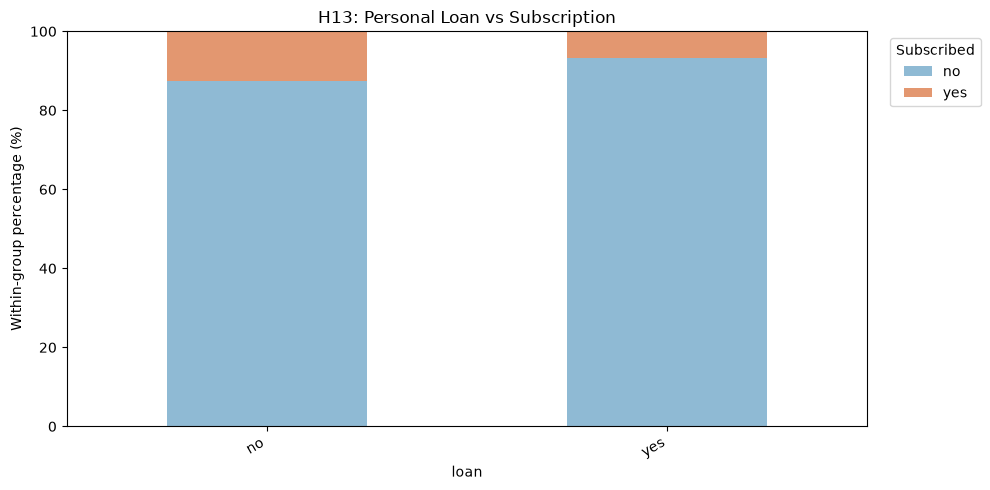

y,no,yes
loan,,
no,87.34,12.66
yes,93.32,6.68


,rate_pct,total
loan,,
no,12.66,37967
yes,6.68,7244


H13: ข้อมูลเชิงพรรณนาสนับสนุนสมมติฐาน


In [30]:
percent_stacked('loan','H13: Personal Loan vs Subscription')
loan_rate=rates_by('loan');display(loan_rate[['rate_pct','total']].round(2))
print('H13:', 'ข้อมูลเชิงพรรณนาสนับสนุนสมมติฐาน' if loan_rate.loc['yes','rate']<loan_rate.loc['no','rate'] else 'ข้อมูลเชิงพรรณนาไม่สนับสนุนสมมติฐาน')

## ข้อ 14 — Contact Method Effect
สมมติฐาน: `cellular` มีอัตราการสมัครมากกว่า `telephone` (ไม่นำ `unknown` มาเปรียบเทียบ)

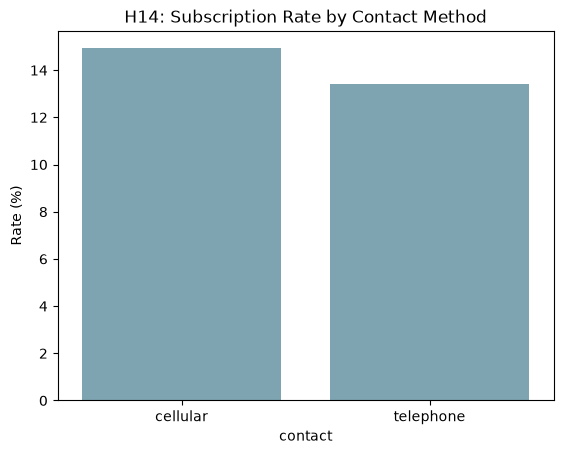

,rate_pct,total
contact,,
cellular,14.92,29285
telephone,13.42,2906


H14: ข้อมูลเชิงพรรณนาสนับสนุนสมมติฐาน


In [31]:
subset=df[df['contact'].isin(['cellular','telephone'])]
contact_rates=rates_by('contact',subset).reindex(['cellular','telephone'])
sns.barplot(x=contact_rates.index,y=contact_rates['rate_pct'].values,color='#75a9b8',errorbar=None)
plt.title('H14: Subscription Rate by Contact Method');plt.ylabel('Rate (%)');plt.show()
display(contact_rates[['rate_pct','total']].round(2))
print('H14:', 'ข้อมูลเชิงพรรณนาสนับสนุนสมมติฐาน' if contact_rates.loc['cellular','rate']>contact_rates.loc['telephone','rate'] else 'ข้อมูลเชิงพรรณนาไม่สนับสนุนสมมติฐาน')

## ข้อ 15 — Campaign Timing Effect
สมมติฐาน: กลุ่มที่สมัครมีจำนวนครั้งติดต่อต่ำกว่า; แสดง Boxplot พร้อมเปรียบเทียบอัตราการสมัครตามจำนวนครั้งด้วย

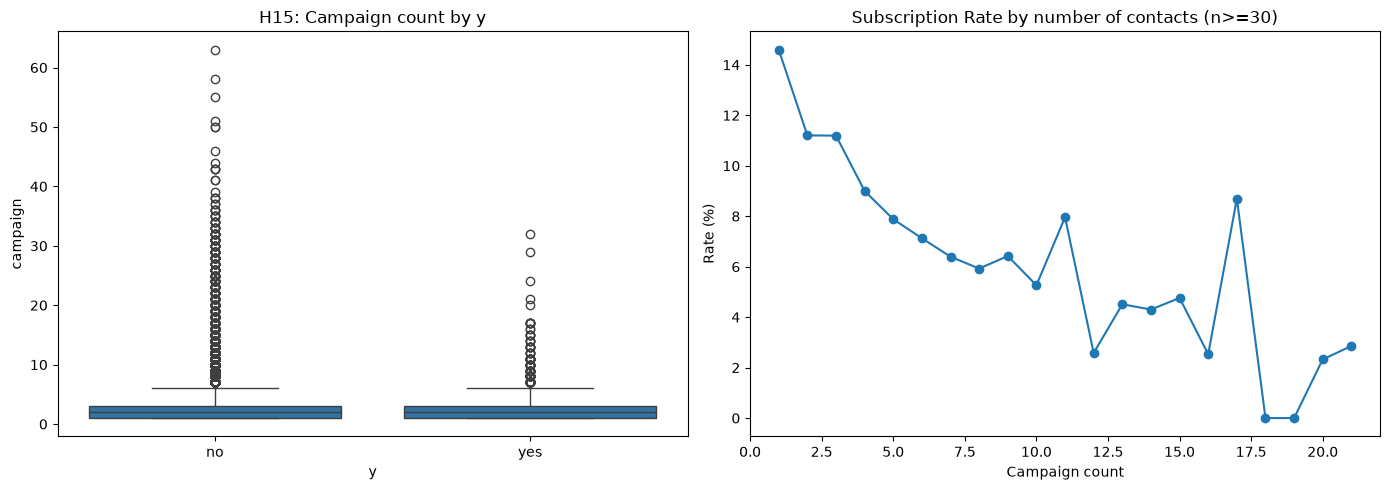

,mean,median,size
y,,,
no,2.85,2.0,39922
yes,2.14,2.0,5289


H15: ข้อมูลเชิงพรรณนาสนับสนุนสมมติฐาน (พิจารณาค่าเฉลี่ย)
หมายเหตุ: การติดต่อหลายครั้งมีความสัมพันธ์กับผลลัพธ์ ไม่ได้พิสูจน์ว่าการติดต่อหลายครั้งเป็นสาเหตุ


In [32]:
fig,ax=plt.subplots(1,2,figsize=(14,5))
sns.boxplot(data=df,x='y',y='campaign',order=['no','yes'],ax=ax[0]);ax[0].set_title('H15: Campaign count by y')
subset_rates=campaign_rates[campaign_rates['size']>=30]
ax[1].plot(subset_rates.index,subset_rates['mean']*100,marker='o')
ax[1].set(title='Subscription Rate by number of contacts (n>=30)',xlabel='Campaign count',ylabel='Rate (%)')
plt.tight_layout();plt.show()
stats=df.groupby('y')['campaign'].agg(['mean','median','size']);display(stats.round(2))
# กรณี median เท่ากัน ใช้ mean ประกอบ พร้อมระบุให้ชัดว่าเป็นการเปรียบเทียบเชิงพรรณนา
support=(stats.loc['yes','mean']<stats.loc['no','mean'])
print('H15:', 'ข้อมูลเชิงพรรณนาสนับสนุนสมมติฐาน (พิจารณาค่าเฉลี่ย)' if support else 'ข้อมูลเชิงพรรณนาไม่สนับสนุนสมมติฐาน (พิจารณาค่าเฉลี่ย)')
print('หมายเหตุ: การติดต่อหลายครั้งมีความสัมพันธ์กับผลลัพธ์ ไม่ได้พิสูจน์ว่าการติดต่อหลายครั้งเป็นสาเหตุ')

## ข้อควรระวังในการเขียนรายงาน
- **Outlier ไม่เท่ากับข้อมูลผิดเสมอไป** ต้องพิจารณาความสมเหตุสมผลก่อนลบ
- **อัตราการสมัคร** คำนวณจากจำนวนผู้สมัครหารด้วยจำนวนทั้งหมด *ภายในแต่ละกลุ่ม*
- **Correlation ไม่ใช่ Causation** และ `pdays=-1` เป็นค่าพิเศษ
- **Duration** เป็นข้อมูลจากการโทรครั้งล่าสุด จึงมีข้อจำกัดเมื่อนำไปใช้คาดการณ์ก่อนโทร
- กราฟรายเดือน/วันที่ไม่ได้พิสูจน์ฤดูกาลที่เกิดซ้ำทุกปีโดยลำพัง
- ตัวอย่างในบางหมวดหมู่อาจน้อย ควรอ่านจำนวน `total` ร่วมกับเปอร์เซ็นต์